# Decision Tree — When Does Pooling Help or Hurt Survival?

Uses `sklearn.tree.DecisionTreeClassifier` to identify which uncertainty
dimensions predict whether a pooling policy improves or damages `safe_rate`
relative to the strict baseline (both levers = 0).

Runs separately for each of the 3 lever combos:
- **Facility only (1,0)**
- **Ambulance only (0,1)**
- **Both (1,1)**

For each combo, five binary trees are trained:
1. **Helps** — Δ safe_rate > 0
2. **Helps a lot** — Δ safe_rate > threshold
3. **Harms** — Δ safe_rate < 0
4. **Harms a lot** — Δ safe_rate < −threshold
5. **4-class** — harms a lot / harms a bit / helps a bit / helps a lot

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

In [2]:
FOLDER_NAME = "20260516_170952_scenario_elia_midterm"
LEVER_COLS  = ["facility_eligibility", "ambulance_eligibility"]
OUTCOME     = "safe_rate"
THRESHOLD   = 0.05  # 5 pp boundary between "a bit" and "a lot" 

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

run_folder = paths.MULTI_RUN_OUTPUT / FOLDER_NAME

df = pd.read_csv(run_folder / "results.csv")
print(f"Loaded {len(df)} runs  |  {df['scenario'].nunique()} scenarios  |  "
      f"{df['policy'].nunique()} distinct policies")

Loaded 16000 runs  |  4000 scenarios  |  320 distinct policies


In [4]:
meta_cols      = ["scenario", "policy", "model"]
meta_start     = min(df.columns.get_loc(c) for c in meta_cols if c in df.columns)
input_cols     = df.columns[:meta_start].tolist()
uncertainty_cols = [c for c in input_cols if c not in LEVER_COLS]

feature_cols = [c for c in uncertainty_cols if c != "seed"]

baseline_mask = df[LEVER_COLS].sum(axis=1) == 0

baseline_outcome = (
    df.loc[baseline_mask]
    .groupby("scenario")[OUTCOME]
    .mean()
    .rename("strict")
)

COMBOS = {
    "Facility only (1,0)": {"facility_eligibility": 1, "ambulance_eligibility": 0},
    "Ambulance only (0,1)": {"facility_eligibility": 0, "ambulance_eligibility": 1},
    "Both (1,1)":           {"facility_eligibility": 1, "ambulance_eligibility": 1},
}

CLASS_NAMES_4 = ["Harms a lot", "Harms a bit", "Helps a bit", "Helps a lot"]

def make_4class(delta, threshold):
    labels = np.full(len(delta), 1, dtype=int)
    labels[delta < -threshold] = 0
    labels[(delta >= 0) & (delta < threshold)] = 2
    labels[delta >= threshold] = 3
    return labels

x_base = (
    df.loc[baseline_mask]
    .drop_duplicates(subset="scenario")
    .set_index("scenario")
)

combo_data = {}
for label, lvls in COMBOS.items():
    mask = pd.Series(True, index=df.index)
    for col, val in lvls.items():
        mask &= df[col] == val
    combo_sr = df.loc[mask].groupby("scenario")[OUTCOME].mean().rename("combo")
    comp = pd.concat([baseline_outcome, combo_sr], axis=1).dropna()
    comp["delta"] = comp["combo"] - comp["strict"]

    X = x_base.loc[comp.index, feature_cols].reset_index(drop=True).astype(float)
    y4 = make_4class(comp["delta"].values, THRESHOLD)
    combo_data[label] = {"comp": comp, "X": X, "y4": y4}

    counts = {CLASS_NAMES_4[i]: (y4 == i).sum() for i in range(4)}
    print(f"{label}:  n={len(comp)}  mean \u0394={comp['delta'].mean():.4f}  "
          + "  ".join(f"{k}: {v}" for k, v in counts.items()))

print(f"\nFeatures ({len(feature_cols)}): {feature_cols}")

Facility only (1,0):  n=4000  mean Δ=-0.0134  Harms a lot: 232  Harms a bit: 2016  Helps a bit: 1751  Helps a lot: 1
Ambulance only (0,1):  n=4000  mean Δ=0.0376  Harms a lot: 157  Harms a bit: 570  Helps a bit: 1689  Helps a lot: 1584
Both (1,1):  n=4000  mean Δ=0.0291  Harms a lot: 211  Harms a bit: 740  Helps a bit: 1755  Helps a lot: 1294

Features (13): ['axp_r1_other_bde_min', 'axp_r1_same_bde_min', 'bcas_rate', 'ccp_r1_inter_bn_min', 'ccp_r1_same_bn_min', 'fraction_t1_bcas', 'fraction_t2_bcas', 'r1_r1_inter_bn_min', 'r1_r2_other_bde_min', 'r1_r2_same_bde_min', 'r2_r2_other_bde_min', 'wave_duration_min', 'waves_per_day']


In [5]:
def run_tree(X, y, label, question, class_names, max_depth=4, test_size=0.3):
    unique, counts_arr = np.unique(y, return_counts=True)
    present = [c for c, n in zip(unique, counts_arr) if n >= 3]

    sep = "=" * 70
    print(sep)
    print(f"  {label} — {question}")
    for c, n in zip(unique, counts_arr):
        cname = class_names[c] if isinstance(class_names, (list, dict)) else str(c)
        print(f"    {cname}: {n}")
    print(sep)

    if len(present) < 2:
        print("  Fewer than 2 classes with >=3 samples — skipping.\n")
        return None, None, None

    present_names = [class_names[c] for c in present]
    mask = np.isin(y, present)
    X_f, y_f = X[mask].reset_index(drop=True), y[mask]

    X_train, X_test, y_train, y_test = train_test_split(
        X_f, y_f, test_size=test_size, random_state=42, stratify=y_f,
    )

    tree = DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_leaf=max(10, int(0.02 * len(y_train))),
        random_state=42,
    )
    tree.fit(X_train, y_train)

    y_pred_test = tree.predict(X_test)
    print(f"  Train acc: {accuracy_score(y_train, tree.predict(X_train)):.3f}  "
          f"Test acc: {accuracy_score(y_test, y_pred_test):.3f}  "
          f"(train={len(X_train)}, test={len(X_test)})")
    print()
    print(classification_report(y_test, y_pred_test,
                                labels=present, target_names=present_names, zero_division=0))

    importances = pd.Series(tree.feature_importances_, index=X_f.columns)
    importances = importances[importances > 0.01].sort_values(ascending=False)
    if not importances.empty:
        print("  Feature importances (>1%):")
        for feat, imp in importances.items():
            print(f"    {feat:30s}  {imp:.3f}")
    print()

    # Confusion matrix only
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred_test, labels=present,
        display_labels=present_names, ax=ax,
        cmap="Blues", colorbar=False,
    )
    ax.set_title(f"{label} — {question}\nConfusion matrix (test set)")
    plt.tight_layout()
    plt.show()

    return tree, X_test, y_test

In [6]:
def display_rules(tree, X_test, y_test, feature_names, class_names, target_class=1, label=""):
    """Extract and display every path leading to target_class with per-rule metrics."""
    if tree is None:
        return

    tree_ = tree.tree_
    if isinstance(class_names, dict):
        idx_to_name = class_names
    else:
        idx_to_name = {i: n for i, n in enumerate(class_names)}

    def fmt_thresh(val):
        """Format threshold with enough precision to avoid ambiguity."""
        if abs(val) < 1:
            return f"{val:.4g}"
        return f"{val:.1f}"

    def recurse(node, path):
        if tree_.children_left[node] == tree_.children_right[node]:
            predicted = tree_.value[node].argmax()
            original_class = tree.classes_[predicted]
            return [(path[:], original_class, tree_.value[node].flatten())]
        feat = feature_names[tree_.feature[node]]
        thresh = tree_.threshold[node]
        t = fmt_thresh(thresh)
        results = []
        results += recurse(tree_.children_left[node],
                           path + [f"{feat} ≤ {t}"])
        results += recurse(tree_.children_right[node],
                           path + [f"{feat} > {t}"])
        return results

    all_paths = recurse(0, [])
    target_paths = [(p, v) for p, cls, v in all_paths if cls == target_class]

    if not target_paths:
        target_n = idx_to_name.get(target_class, target_class)
        print(f"  No paths lead to class {target_n}.\n")
        return

    target_name = idx_to_name.get(target_class, str(target_class))
    sep = "=" * 70
    print(f"\n{sep}")
    print(f"  {label} — Rules predicting: {target_name}")
    print(f"{sep}\n")

    y_pred_all = tree.predict(X_test)
    leaf_ids = tree.apply(X_test)

    def get_leaf_id(path):
        node = 0
        for condition in path:
            if "≤" in condition:
                node = tree_.children_left[node]
            else:
                node = tree_.children_right[node]
        return node

    for i, (path, train_values) in enumerate(target_paths, 1):
        leaf_node = get_leaf_id(path)
        in_leaf = leaf_ids == leaf_node
        n_test = in_leaf.sum()

        if n_test == 0:
            continue

        correct = ((y_pred_all == target_class) & (y_test == target_class) & in_leaf).sum()
        predicted_pos = (y_pred_all[in_leaf] == target_class).sum()
        actual_pos = (y_test[in_leaf] == target_class).sum()
        total_actual_pos = (y_test == target_class).sum()

        precision = correct / predicted_pos if predicted_pos > 0 else 0
        recall = correct / total_actual_pos if total_actual_pos > 0 else 0

        print(f"  Rule {i}:")
        for j, cond in enumerate(path):
            prefix = "  IF  " if j == 0 else "  AND "
            print(f"    {prefix}{cond}")
        print(f"    → {target_name}")
        print(f"    Test: {n_test} samples | precision={precision:.0%} | "
              f"recall={recall:.0%} (covers {correct}/{total_actual_pos} positives)")
        print()

## Facility only (1,0)

In [7]:
cd = combo_data["Facility only (1,0)"]
X, comp = cd["X"], cd["comp"]

  Facility only (1,0) — Does pooling help? (Δ > 0)
    No: 3586
    Yes: 414
  Train acc: 0.896  Test acc: 0.897  (train=2800, test=1200)

              precision    recall  f1-score   support

          No       0.90      1.00      0.95      1076
         Yes       0.00      0.00      0.00       124

    accuracy                           0.90      1200
   macro avg       0.45      0.50      0.47      1200
weighted avg       0.80      0.90      0.85      1200

  Feature importances (>1%):
    bcas_rate                       0.546
    fraction_t1_bcas                0.157
    fraction_t2_bcas                0.093
    ccp_r1_same_bn_min              0.077
    waves_per_day                   0.065
    r1_r2_same_bde_min              0.062



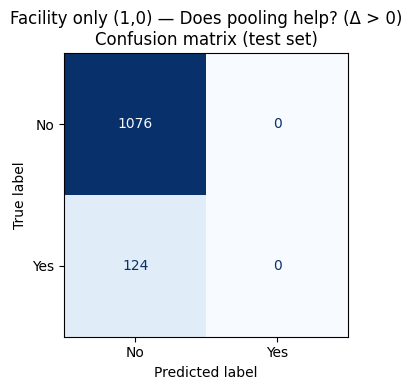

In [8]:
tree_fac_helps, X_test_fac_h, y_test_fac_h = run_tree(
    X, (comp["delta"] > 0).astype(int).values,
    "Facility only (1,0)", "Does pooling help? (\u0394 > 0)",
    class_names={0: "No", 1: "Yes"},
)

In [9]:
display_rules(tree_fac_helps, X_test_fac_h, y_test_fac_h,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Facility only (1,0) — helps")

  No paths lead to class Yes.



In [10]:
tree_fac_lot, X_test_fac_l, y_test_fac_l = run_tree(
    X, (comp["delta"] > THRESHOLD).astype(int).values,
    "Facility only (1,0)", f"Does pooling help a lot? (\u0394 > {THRESHOLD:.0%})",
    class_names={0: "No", 1: "Yes"},
)

  Facility only (1,0) — Does pooling help a lot? (Δ > 5%)
    No: 3999
    Yes: 1
  Fewer than 2 classes with >=3 samples — skipping.



In [11]:
display_rules(tree_fac_lot, X_test_fac_l, y_test_fac_l,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Facility only (1,0) — helps a lot")

  Facility only (1,0) — Does pooling harm? (Δ < 0)
    No: 1752
    Yes: 2248
  Train acc: 0.842  Test acc: 0.836  (train=2800, test=1200)

              precision    recall  f1-score   support

          No       0.90      0.71      0.79       526
         Yes       0.80      0.94      0.86       674

    accuracy                           0.84      1200
   macro avg       0.85      0.82      0.83      1200
weighted avg       0.84      0.84      0.83      1200

  Feature importances (>1%):
    bcas_rate                       0.888
    fraction_t2_bcas                0.055
    fraction_t1_bcas                0.043



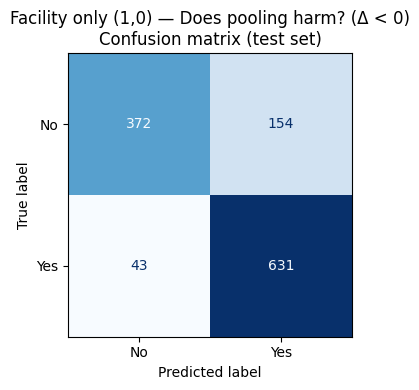

In [12]:
tree_fac_harms, X_test_fac_hr, y_test_fac_hr = run_tree(
    X, (comp["delta"] < 0).astype(int).values,
    "Facility only (1,0)", "Does pooling harm? (\u0394 < 0)",
    class_names={0: "No", 1: "Yes"},
)

In [13]:
display_rules(tree_fac_harms, X_test_fac_hr, y_test_fac_hr,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Facility only (1,0) — harms")


  Facility only (1,0) — harms — Rules predicting: Yes



  Rule 1:
      IF  bcas_rate ≤ 0.03765
      AND bcas_rate > 0.02355
      AND fraction_t1_bcas > 0.14
      AND fraction_t2_bcas > 0.285
    → Yes
    Test: 55 samples | precision=51% | recall=4% (covers 28/674 positives)

  Rule 2:
      IF  bcas_rate > 0.03765
      AND bcas_rate ≤ 0.05068
      AND fraction_t2_bcas ≤ 0.2335
      AND fraction_t1_bcas > 0.205
    → Yes
    Test: 46 samples | precision=72% | recall=5% (covers 33/674 positives)

  Rule 3:
      IF  bcas_rate > 0.03765
      AND bcas_rate ≤ 0.05068
      AND fraction_t2_bcas > 0.2335
      AND axp_r1_same_bde_min ≤ 61.0
    → Yes
    Test: 48 samples | precision=69% | recall=5% (covers 33/674 positives)

  Rule 4:
      IF  bcas_rate > 0.03765
      AND bcas_rate ≤ 0.05068
      AND fraction_t2_bcas > 0.2335
      AND axp_r1_same_bde_min > 61.0
    → Yes
    Test: 29 samples | precision=69% | recall=3% (covers 20/674 positives)

  Rule 5:
      IF  bcas_rate > 0.03765
      AND bcas_rate > 0.05068
      AND fraction_t

  Facility only (1,0) — Does pooling harm a lot? (Δ < -5%)
    No: 3768
    Yes: 232
  Train acc: 0.942  Test acc: 0.942  (train=2800, test=1200)

              precision    recall  f1-score   support

          No       0.94      1.00      0.97      1130
         Yes       0.00      0.00      0.00        70

    accuracy                           0.94      1200
   macro avg       0.47      0.50      0.48      1200
weighted avg       0.89      0.94      0.91      1200

  Feature importances (>1%):
    bcas_rate                       0.295
    r1_r2_same_bde_min              0.275
    r1_r2_other_bde_min             0.194
    fraction_t1_bcas                0.174
    r1_r1_inter_bn_min              0.029
    ccp_r1_same_bn_min              0.023



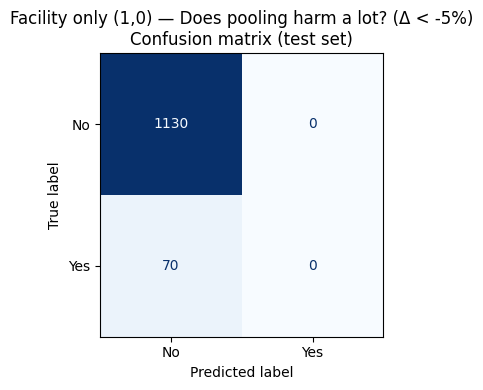

In [14]:
tree_fac_hlot, X_test_fac_hl, y_test_fac_hl = run_tree(
    X, (comp["delta"] < -THRESHOLD).astype(int).values,
    "Facility only (1,0)", f"Does pooling harm a lot? (\u0394 < -{THRESHOLD:.0%})",
    class_names={0: "No", 1: "Yes"},
)

In [15]:
display_rules(tree_fac_hlot, X_test_fac_hl, y_test_fac_hl,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Facility only (1,0) — harms a lot")

  No paths lead to class Yes.



  Facility only (1,0) — 4-class
    Harms a lot: 232
    Harms a bit: 2016
    Helps a bit: 1751
    Helps a lot: 1
  Train acc: 0.782  Test acc: 0.779  (train=2799, test=1200)

              precision    recall  f1-score   support

 Harms a lot       0.00      0.00      0.00        70
 Harms a bit       0.73      0.89      0.80       605
 Helps a bit       0.85      0.76      0.80       525

    accuracy                           0.78      1200
   macro avg       0.53      0.55      0.54      1200
weighted avg       0.74      0.78      0.76      1200

  Feature importances (>1%):
    bcas_rate                       0.886
    fraction_t1_bcas                0.049
    fraction_t2_bcas                0.033
    r1_r2_same_bde_min              0.018
    r1_r2_other_bde_min             0.015



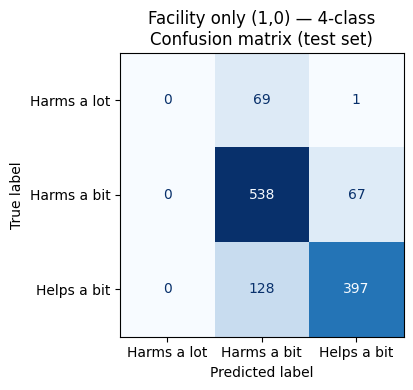

In [16]:
tree_fac_4c, X_test_fac_4, y_test_fac_4 = run_tree(
    cd["X"], cd["y4"],
    "Facility only (1,0)", "4-class",
    class_names=CLASS_NAMES_4,
)

In [17]:
for tc in range(4):
    display_rules(tree_fac_4c, X_test_fac_4, y_test_fac_4,
                  feature_cols, CLASS_NAMES_4, target_class=tc,
                  label="Facility only (1,0) — 4-class")

  No paths lead to class Harms a lot.


  Facility only (1,0) — 4-class — Rules predicting: Harms a bit

  Rule 1:
      IF  bcas_rate ≤ 0.04002
      AND bcas_rate > 0.02808
      AND fraction_t1_bcas > 0.1961
      AND r1_r2_other_bde_min ≤ 96.8
    → Harms a bit
    Test: 40 samples | precision=55% | recall=4% (covers 22/605 positives)

  Rule 2:
      IF  bcas_rate > 0.04002
      AND bcas_rate ≤ 0.05068
      AND fraction_t1_bcas > 0.1135
      AND fraction_t2_bcas ≤ 0.3468
    → Harms a bit
    Test: 75 samples | precision=72% | recall=9% (covers 54/605 positives)

  Rule 3:
      IF  bcas_rate > 0.04002
      AND bcas_rate ≤ 0.05068
      AND fraction_t1_bcas > 0.1135
      AND fraction_t2_bcas > 0.3468
    → Harms a bit
    Test: 24 samples | precision=71% | recall=3% (covers 17/605 positives)

  Rule 4:
      IF  bcas_rate > 0.04002
      AND bcas_rate > 0.05068
      AND r1_r2_same_bde_min ≤ 54.3
      AND fraction_t1_bcas ≤ 0.3221
    → Harms a bit
    Test: 108 samples | pr

## Ambulance only (0,1)

In [18]:
cd = combo_data["Ambulance only (0,1)"]
X, comp = cd["X"], cd["comp"]

  Ambulance only (0,1) — Does pooling help? (Δ > 0)
    No: 1100
    Yes: 2900
  Train acc: 0.858  Test acc: 0.847  (train=2800, test=1200)

              precision    recall  f1-score   support

          No       0.71      0.74      0.73       330
         Yes       0.90      0.89      0.89       870

    accuracy                           0.85      1200
   macro avg       0.81      0.81      0.81      1200
weighted avg       0.85      0.85      0.85      1200

  Feature importances (>1%):
    bcas_rate                       0.492
    fraction_t1_bcas                0.351
    r1_r2_other_bde_min             0.115
    waves_per_day                   0.043



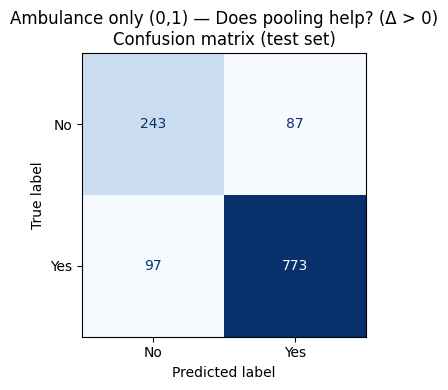

In [19]:
tree_amb_helps, X_test_amb_h, y_test_amb_h = run_tree(
    X, (comp["delta"] > 0).astype(int).values,
    "Ambulance only (0,1)", "Does pooling help? (\u0394 > 0)",
    class_names={0: "No", 1: "Yes"},
)

In [20]:
display_rules(tree_amb_helps, X_test_amb_h, y_test_amb_h,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Ambulance only (0,1) — helps")


  Ambulance only (0,1) — helps — Rules predicting: Yes

  Rule 1:
      IF  fraction_t1_bcas ≤ 0.3319
      AND bcas_rate > 0.008453
      AND fraction_t1_bcas ≤ 0.2793
      AND bcas_rate ≤ 0.01769
    → Yes
    Test: 63 samples | precision=78% | recall=6% (covers 49/870 positives)

  Rule 2:
      IF  fraction_t1_bcas ≤ 0.3319
      AND bcas_rate > 0.008453
      AND fraction_t1_bcas ≤ 0.2793
      AND bcas_rate > 0.01769
    → Yes
    Test: 562 samples | precision=95% | recall=61% (covers 534/870 positives)

  Rule 3:
      IF  fraction_t1_bcas ≤ 0.3319
      AND bcas_rate > 0.008453
      AND fraction_t1_bcas > 0.2793
      AND r1_r2_other_bde_min ≤ 95.0
    → Yes
    Test: 50 samples | precision=84% | recall=5% (covers 42/870 positives)

  Rule 4:
      IF  fraction_t1_bcas ≤ 0.3319
      AND bcas_rate > 0.008453
      AND fraction_t1_bcas > 0.2793
      AND r1_r2_other_bde_min > 95.0
    → Yes
    Test: 55 samples | precision=67% | recall=4% (covers 37/870 positives)

  Rule 5:


  Ambulance only (0,1) — Does pooling help a lot? (Δ > 5%)
    No: 2416
    Yes: 1584


  Train acc: 0.801  Test acc: 0.767  (train=2800, test=1200)



              precision    recall  f1-score   support

          No       0.78      0.86      0.82       725
         Yes       0.74      0.63      0.68       475

    accuracy                           0.77      1200
   macro avg       0.76      0.74      0.75      1200
weighted avg       0.77      0.77      0.76      1200

  Feature importances (>1%):
    fraction_t1_bcas                0.469
    bcas_rate                       0.467
    r1_r2_other_bde_min             0.038
    waves_per_day                   0.014
    fraction_t2_bcas                0.010



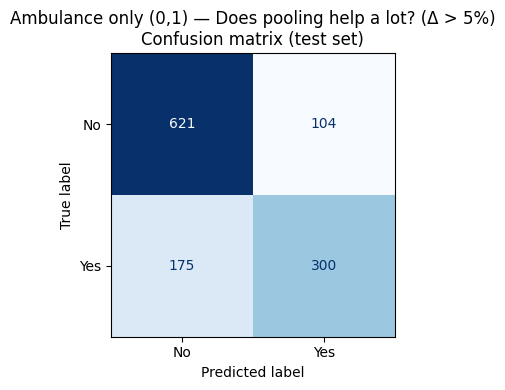

In [21]:
tree_amb_lot, X_test_amb_l, y_test_amb_l = run_tree(
    X, (comp["delta"] > THRESHOLD).astype(int).values,
    "Ambulance only (0,1)", f"Does pooling help a lot? (\u0394 > {THRESHOLD:.0%})",
    class_names={0: "No", 1: "Yes"},
)

In [22]:
display_rules(tree_amb_lot, X_test_amb_l, y_test_amb_l,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Ambulance only (0,1) — helps a lot")


  Ambulance only (0,1) — helps a lot — Rules predicting: Yes



  Rule 1:
      IF  fraction_t1_bcas ≤ 0.2483
      AND bcas_rate > 0.02857
      AND fraction_t1_bcas ≤ 0.1565
      AND bcas_rate ≤ 0.03636
    → Yes
    Test: 28 samples | precision=71% | recall=4% (covers 20/475 positives)

  Rule 2:
      IF  fraction_t1_bcas ≤ 0.2483
      AND bcas_rate > 0.02857
      AND fraction_t1_bcas ≤ 0.1565
      AND bcas_rate > 0.03636
    → Yes
    Test: 240 samples | precision=84% | recall=42% (covers 201/475 positives)

  Rule 3:
      IF  fraction_t1_bcas ≤ 0.2483
      AND bcas_rate > 0.02857
      AND fraction_t1_bcas > 0.1565
      AND bcas_rate ≤ 0.05319
    → Yes
    Test: 48 samples | precision=69% | recall=7% (covers 33/475 positives)

  Rule 4:
      IF  fraction_t1_bcas > 0.2483
      AND bcas_rate ≤ 0.04371
      AND r1_r2_other_bde_min ≤ 98.6
      AND bcas_rate > 0.01443
    → Yes
    Test: 88 samples | precision=52% | recall=10% (covers 46/475 positives)



  Ambulance only (0,1) — Does pooling harm? (Δ < 0)
    No: 3273
    Yes: 727


  Train acc: 0.892  Test acc: 0.901  (train=2800, test=1200)

              precision    recall  f1-score   support

          No       0.96      0.92      0.94       982
         Yes       0.69      0.82      0.75       218

    accuracy                           0.90      1200
   macro avg       0.83      0.87      0.84      1200
weighted avg       0.91      0.90      0.90      1200

  Feature importances (>1%):
    fraction_t1_bcas                0.495
    bcas_rate                       0.331
    r1_r2_other_bde_min             0.141
    waves_per_day                   0.033



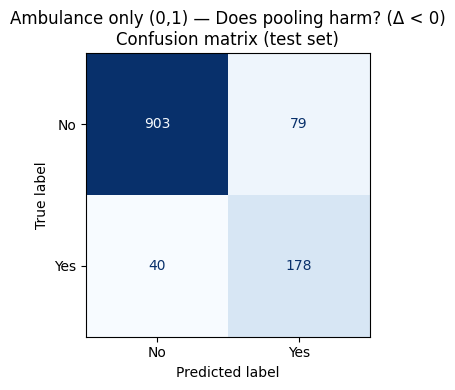

In [23]:
tree_amb_harms, X_test_amb_hr, y_test_amb_hr = run_tree(
    X, (comp["delta"] < 0).astype(int).values,
    "Ambulance only (0,1)", "Does pooling harm? (\u0394 < 0)",
    class_names={0: "No", 1: "Yes"},
)

In [24]:
display_rules(tree_amb_harms, X_test_amb_hr, y_test_amb_hr,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Ambulance only (0,1) — harms")


  Ambulance only (0,1) — harms — Rules predicting: Yes

  Rule 1:
      IF  fraction_t1_bcas ≤ 0.3248
      AND fraction_t1_bcas > 0.2685
      AND bcas_rate > 0.04178
      AND r1_r2_other_bde_min > 99.5
    → Yes
    Test: 26 samples | precision=42% | recall=5% (covers 11/218 positives)

  Rule 2:
      IF  fraction_t1_bcas > 0.3248
      AND bcas_rate > 0.03713
      AND r1_r2_other_bde_min ≤ 93.5
      AND waves_per_day > 2.5
    → Yes
    Test: 78 samples | precision=59% | recall=21% (covers 46/218 positives)

  Rule 3:
      IF  fraction_t1_bcas > 0.3248
      AND bcas_rate > 0.03713
      AND r1_r2_other_bde_min > 93.5
      AND fraction_t1_bcas ≤ 0.3931
    → Yes
    Test: 52 samples | precision=71% | recall=17% (covers 37/218 positives)

  Rule 4:
      IF  fraction_t1_bcas > 0.3248
      AND bcas_rate > 0.03713
      AND r1_r2_other_bde_min > 93.5
      AND fraction_t1_bcas > 0.3931
    → Yes
    Test: 101 samples | precision=83% | recall=39% (covers 84/218 positives)



  Ambulance only (0,1) — Does pooling harm a lot? (Δ < -5%)
    No: 3843
    Yes: 157
  Train acc: 0.963  Test acc: 0.962  (train=2800, test=1200)

              precision    recall  f1-score   support

          No       0.97      0.99      0.98      1153
         Yes       0.53      0.21      0.30        47

    accuracy                           0.96      1200
   macro avg       0.75      0.60      0.64      1200
weighted avg       0.95      0.96      0.95      1200

  Feature importances (>1%):
    fraction_t1_bcas                0.390
    r1_r2_other_bde_min             0.317
    bcas_rate                       0.229
    axp_r1_other_bde_min            0.054



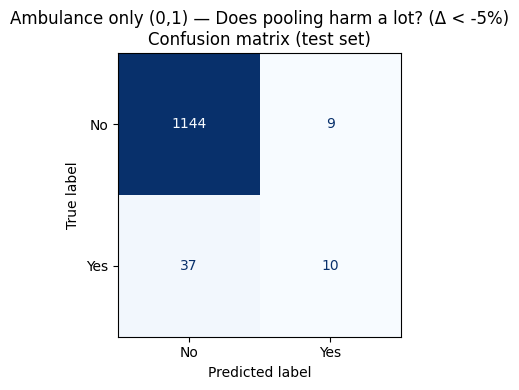

In [25]:
tree_amb_hlot, X_test_amb_hl, y_test_amb_hl = run_tree(
    X, (comp["delta"] < -THRESHOLD).astype(int).values,
    "Ambulance only (0,1)", f"Does pooling harm a lot? (\u0394 < -{THRESHOLD:.0%})",
    class_names={0: "No", 1: "Yes"},
)

In [26]:
display_rules(tree_amb_hlot, X_test_amb_hl, y_test_amb_hl,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Ambulance only (0,1) — harms a lot")


  Ambulance only (0,1) — harms a lot — Rules predicting: Yes

  Rule 1:
      IF  fraction_t1_bcas > 0.4013
      AND r1_r2_other_bde_min > 105.0
      AND bcas_rate > 0.03744
      AND axp_r1_other_bde_min ≤ 97.3
    → Yes
    Test: 19 samples | precision=53% | recall=21% (covers 10/47 positives)



  Ambulance only (0,1) — 4-class
    Harms a lot: 157
    Harms a bit: 570
    Helps a bit: 1689
    Helps a lot: 1584
  Train acc: 0.680  Test acc: 0.647  (train=2800, test=1200)

              precision    recall  f1-score   support

 Harms a lot       0.00      0.00      0.00        47
 Harms a bit       0.48      0.68      0.56       171
 Helps a bit       0.65      0.61      0.63       507
 Helps a lot       0.73      0.74      0.73       475

    accuracy                           0.65      1200
   macro avg       0.46      0.51      0.48      1200
weighted avg       0.63      0.65      0.64      1200

  Feature importances (>1%):
    fraction_t1_bcas                0.477
    bcas_rate                       0.451
    r1_r2_other_bde_min             0.069



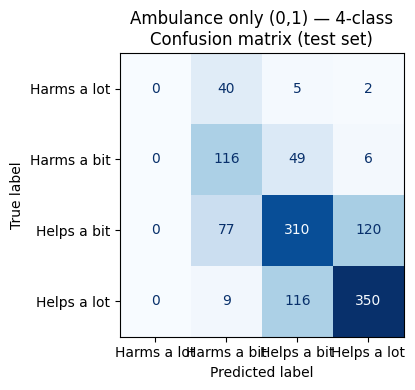

In [27]:
tree_amb_4c, X_test_amb_4, y_test_amb_4 = run_tree(
    cd["X"], cd["y4"],
    "Ambulance only (0,1)", "4-class",
    class_names=CLASS_NAMES_4,
)

In [28]:
for tc in range(4):
    display_rules(tree_amb_4c, X_test_amb_4, y_test_amb_4,
                  feature_cols, CLASS_NAMES_4, target_class=tc,
                  label="Ambulance only (0,1) — 4-class")

  No paths lead to class Harms a lot.


  Ambulance only (0,1) — 4-class — Rules predicting: Harms a bit

  Rule 1:
      IF  bcas_rate > 0.02234
      AND fraction_t1_bcas > 0.2554
      AND bcas_rate > 0.04498
      AND fraction_t1_bcas > 0.3328
    → Harms a bit
    Test: 242 samples | precision=48% | recall=68% (covers 116/171 positives)


  Ambulance only (0,1) — 4-class — Rules predicting: Helps a bit

  Rule 1:
      IF  bcas_rate ≤ 0.02234
      AND bcas_rate ≤ 0.01452
      AND bcas_rate ≤ 0.007191
      AND bcas_rate ≤ 0.004815
    → Helps a bit
    Test: 45 samples | precision=98% | recall=9% (covers 44/507 positives)

  Rule 2:
      IF  bcas_rate ≤ 0.02234
      AND bcas_rate ≤ 0.01452
      AND bcas_rate ≤ 0.007191
      AND bcas_rate > 0.004815
    → Helps a bit
    Test: 31 samples | precision=100% | recall=6% (covers 31/507 positives)

  Rule 3:
      IF  bcas_rate ≤ 0.02234
      AND bcas_rate ≤ 0.01452
      AND bcas_rate > 0.007191
      AND axp_r1_other_bde_min ≤ 9

## Both (1,1)

In [29]:
cd = combo_data["Both (1,1)"]
X, comp = cd["X"], cd["comp"]

  Both (1,1) — Does pooling help? (Δ > 0)
    No: 1314
    Yes: 2686
  Train acc: 0.835  Test acc: 0.823  (train=2800, test=1200)

              precision    recall  f1-score   support

          No       0.81      0.60      0.69       394
         Yes       0.83      0.93      0.88       806

    accuracy                           0.82      1200
   macro avg       0.82      0.77      0.78      1200
weighted avg       0.82      0.82      0.82      1200

  Feature importances (>1%):
    bcas_rate                       0.476
    fraction_t1_bcas                0.376
    waves_per_day                   0.070
    r1_r2_other_bde_min             0.054
    wave_duration_min               0.015



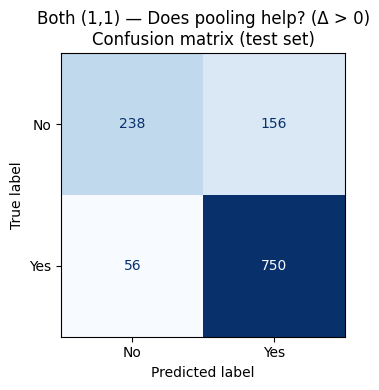

In [30]:
tree_both_helps, X_test_both_h, y_test_both_h = run_tree(
    X, (comp["delta"] > 0).astype(int).values,
    "Both (1,1)", "Does pooling help? (\u0394 > 0)",
    class_names={0: "No", 1: "Yes"},
)

In [31]:
display_rules(tree_both_helps, X_test_both_h, y_test_both_h,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Both (1,1) — helps")


  Both (1,1) — helps — Rules predicting: Yes

  Rule 1:
      IF  fraction_t1_bcas ≤ 0.3244
      AND bcas_rate > 0.008453
      AND fraction_t1_bcas ≤ 0.2663
      AND bcas_rate ≤ 0.01442
    → Yes
    Test: 38 samples | precision=68% | recall=3% (covers 26/806 positives)

  Rule 2:
      IF  fraction_t1_bcas ≤ 0.3244
      AND bcas_rate > 0.008453
      AND fraction_t1_bcas ≤ 0.2663
      AND bcas_rate > 0.01442
    → Yes
    Test: 555 samples | precision=93% | recall=64% (covers 514/806 positives)

  Rule 3:
      IF  fraction_t1_bcas ≤ 0.3244
      AND bcas_rate > 0.008453
      AND fraction_t1_bcas > 0.2663
      AND bcas_rate ≤ 0.04373
    → Yes
    Test: 55 samples | precision=85% | recall=6% (covers 47/806 positives)

  Rule 4:
      IF  fraction_t1_bcas ≤ 0.3244
      AND bcas_rate > 0.008453
      AND fraction_t1_bcas > 0.2663
      AND bcas_rate > 0.04373
    → Yes
    Test: 79 samples | precision=53% | recall=5% (covers 42/806 positives)

  Rule 5:
      IF  fraction_t1_bc

  Both (1,1) — Does pooling help a lot? (Δ > 5%)
    No: 2706
    Yes: 1294
  Train acc: 0.788  Test acc: 0.772  (train=2800, test=1200)

              precision    recall  f1-score   support

          No       0.82      0.84      0.83       812
         Yes       0.65      0.63      0.64       388

    accuracy                           0.77      1200
   macro avg       0.74      0.73      0.74      1200
weighted avg       0.77      0.77      0.77      1200

  Feature importances (>1%):
    bcas_rate                       0.463
    fraction_t1_bcas                0.430
    r1_r2_other_bde_min             0.096
    ccp_r1_same_bn_min              0.011



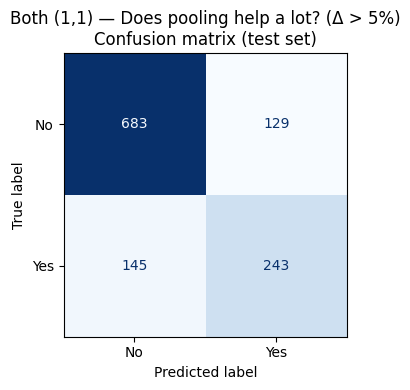

In [32]:
tree_both_lot, X_test_both_l, y_test_both_l = run_tree(
    X, (comp["delta"] > THRESHOLD).astype(int).values,
    "Both (1,1)", f"Does pooling help a lot? (\u0394 > {THRESHOLD:.0%})",
    class_names={0: "No", 1: "Yes"},
)

In [33]:
display_rules(tree_both_lot, X_test_both_l, y_test_both_l,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Both (1,1) — helps a lot")


  Both (1,1) — helps a lot — Rules predicting: Yes

  Rule 1:
      IF  fraction_t1_bcas ≤ 0.2064
      AND bcas_rate > 0.02743
      AND fraction_t1_bcas ≤ 0.07575
      AND ccp_r1_same_bn_min ≤ 11.0
    → Yes
    Test: 62 samples | precision=79% | recall=13% (covers 49/388 positives)

  Rule 2:
      IF  fraction_t1_bcas ≤ 0.2064
      AND bcas_rate > 0.02743
      AND fraction_t1_bcas ≤ 0.07575
      AND ccp_r1_same_bn_min > 11.0
    → Yes
    Test: 84 samples | precision=81% | recall=18% (covers 68/388 positives)

  Rule 3:
      IF  fraction_t1_bcas ≤ 0.2064
      AND bcas_rate > 0.02743
      AND fraction_t1_bcas > 0.07575
      AND r1_r2_other_bde_min ≤ 97.5
    → Yes
    Test: 118 samples | precision=73% | recall=22% (covers 86/388 positives)

  Rule 4:
      IF  fraction_t1_bcas > 0.2064
      AND bcas_rate ≤ 0.042
      AND bcas_rate > 0.01243
      AND r1_r2_other_bde_min ≤ 98.6
    → Yes
    Test: 108 samples | precision=37% | recall=10% (covers 40/388 positives)



  Both (1,1) — Does pooling harm? (Δ < 0)
    No: 3049
    Yes: 951
  Train acc: 0.879  Test acc: 0.880  (train=2800, test=1200)

              precision    recall  f1-score   support

          No       0.93      0.92      0.92       915
         Yes       0.74      0.76      0.75       285

    accuracy                           0.88      1200
   macro avg       0.83      0.84      0.84      1200
weighted avg       0.88      0.88      0.88      1200

  Feature importances (>1%):
    fraction_t1_bcas                0.468
    bcas_rate                       0.384
    r1_r2_other_bde_min             0.083
    waves_per_day                   0.065



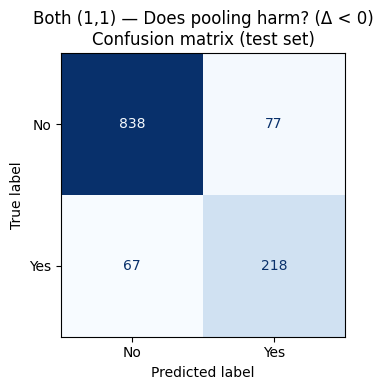

In [34]:
tree_both_harms, X_test_both_hr, y_test_both_hr = run_tree(
    X, (comp["delta"] < 0).astype(int).values,
    "Both (1,1)", "Does pooling harm? (\u0394 < 0)",
    class_names={0: "No", 1: "Yes"},
)

In [35]:
display_rules(tree_both_harms, X_test_both_hr, y_test_both_hr,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Both (1,1) — harms")


  Both (1,1) — harms — Rules predicting: Yes



  Rule 1:
      IF  fraction_t1_bcas ≤ 0.3196
      AND fraction_t1_bcas > 0.2665
      AND bcas_rate > 0.0419
      AND r1_r2_other_bde_min > 88.5
    → Yes
    Test: 40 samples | precision=48% | recall=7% (covers 19/285 positives)

  Rule 2:
      IF  fraction_t1_bcas > 0.3196
      AND bcas_rate > 0.03713
      AND waves_per_day > 1.5
      AND r1_r2_other_bde_min ≤ 93.1
    → Yes
    Test: 97 samples | precision=67% | recall=23% (covers 65/285 positives)

  Rule 3:
      IF  fraction_t1_bcas > 0.3196
      AND bcas_rate > 0.03713
      AND waves_per_day > 1.5
      AND r1_r2_other_bde_min > 93.1
    → Yes
    Test: 158 samples | precision=85% | recall=47% (covers 134/285 positives)



  Both (1,1) — Does pooling harm a lot? (Δ < -5%)
    No: 3789
    Yes: 211


  Train acc: 0.951  Test acc: 0.951  (train=2800, test=1200)

              precision    recall  f1-score   support

          No       0.98      0.97      0.97      1137
         Yes       0.53      0.56      0.54        63

    accuracy                           0.95      1200
   macro avg       0.75      0.76      0.76      1200
weighted avg       0.95      0.95      0.95      1200

  Feature importances (>1%):
    fraction_t1_bcas                0.343
    r1_r2_other_bde_min             0.235
    bcas_rate                       0.233
    waves_per_day                   0.179



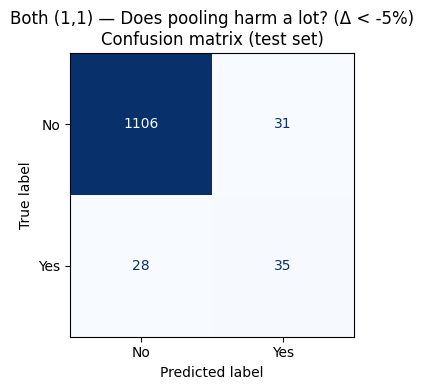

In [36]:
tree_both_hlot, X_test_both_hl, y_test_both_hl = run_tree(
    X, (comp["delta"] < -THRESHOLD).astype(int).values,
    "Both (1,1)", f"Does pooling harm a lot? (\u0394 < -{THRESHOLD:.0%})",
    class_names={0: "No", 1: "Yes"},
)

In [37]:
display_rules(tree_both_hlot, X_test_both_hl, y_test_both_hl,
              feature_cols, {0: "No", 1: "Yes"}, target_class=1,
              label="Both (1,1) — harms a lot")


  Both (1,1) — harms a lot — Rules predicting: Yes

  Rule 1:
      IF  fraction_t1_bcas > 0.3975
      AND r1_r2_other_bde_min > 92.4
      AND bcas_rate > 0.03744
      AND waves_per_day > 3.5
    → Yes
    Test: 66 samples | precision=53% | recall=56% (covers 35/63 positives)



  Both (1,1) — 4-class
    Harms a lot: 211
    Harms a bit: 740
    Helps a bit: 1755
    Helps a lot: 1294


  Train acc: 0.629  Test acc: 0.575  (train=2800, test=1200)



              precision    recall  f1-score   support

 Harms a lot       0.00      0.00      0.00        63
 Harms a bit       0.48      0.66      0.55       222
 Helps a bit       0.60      0.59      0.59       527
 Helps a lot       0.62      0.60      0.61       388

    accuracy                           0.57      1200
   macro avg       0.42      0.46      0.44      1200
weighted avg       0.55      0.57      0.56      1200

  Feature importances (>1%):
    bcas_rate                       0.479
    fraction_t1_bcas                0.398
    r1_r2_other_bde_min             0.089
    waves_per_day                   0.032



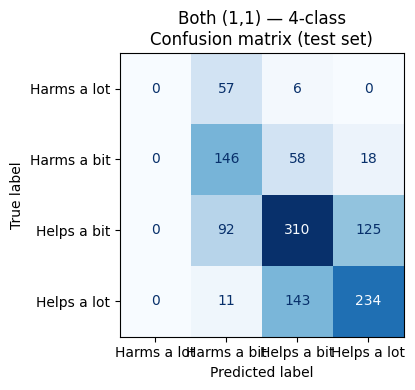

In [38]:
tree_both_4c, X_test_both_4, y_test_both_4 = run_tree(
    cd["X"], cd["y4"],
    "Both (1,1)", "4-class",
    class_names=CLASS_NAMES_4,
)

In [39]:
for tc in range(4):
    display_rules(tree_both_4c, X_test_both_4, y_test_both_4,
                  feature_cols, CLASS_NAMES_4, target_class=tc,
                  label="Both (1,1) — 4-class")

  No paths lead to class Harms a lot.


  Both (1,1) — 4-class — Rules predicting: Harms a bit

  Rule 1:
      IF  fraction_t1_bcas > 0.28
      AND bcas_rate > 0.03632
      AND r1_r2_other_bde_min ≤ 93.4
      AND waves_per_day > 2.5
    → Harms a bit
    Test: 110 samples | precision=48% | recall=24% (covers 53/222 positives)

  Rule 2:
      IF  fraction_t1_bcas > 0.28
      AND bcas_rate > 0.03632
      AND r1_r2_other_bde_min > 93.4
      AND fraction_t1_bcas ≤ 0.3964
    → Harms a bit
    Test: 104 samples | precision=44% | recall=21% (covers 46/222 positives)

  Rule 3:
      IF  fraction_t1_bcas > 0.28
      AND bcas_rate > 0.03632
      AND r1_r2_other_bde_min > 93.4
      AND fraction_t1_bcas > 0.3964
    → Harms a bit
    Test: 92 samples | precision=51% | recall=21% (covers 47/222 positives)


  Both (1,1) — 4-class — Rules predicting: Helps a bit

  Rule 1:
      IF  fraction_t1_bcas ≤ 0.28
      AND bcas_rate ≤ 0.02485
      AND bcas_rate ≤ 0.01218
      AND ccp_r1_same

## Summary — Feature Importance Across All Trees

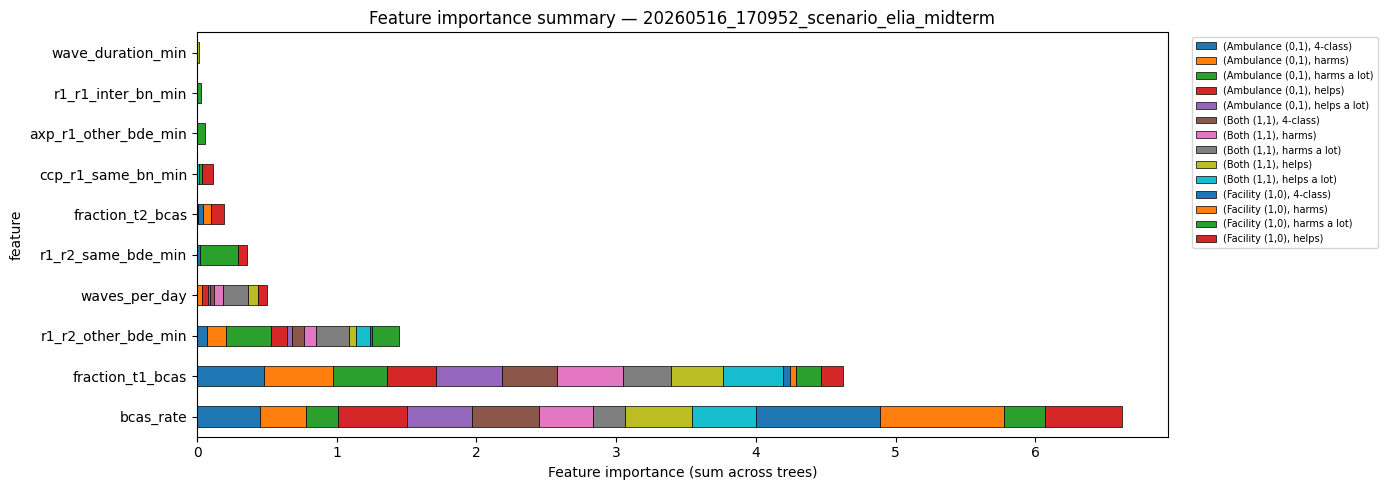

combo                Ambulance (0,1)                                        \
question                     4-class  harms harms a lot  helps helps a lot   
feature                                                                      
bcas_rate                      0.451  0.331       0.229  0.492       0.467   
fraction_t1_bcas               0.477  0.495       0.390  0.351       0.469   
r1_r2_other_bde_min            0.069  0.141       0.317  0.115       0.038   
waves_per_day                  0.000  0.033       0.000  0.043       0.014   
r1_r2_same_bde_min             0.000  0.000       0.000  0.000       0.000   
fraction_t2_bcas               0.000  0.000       0.000  0.000       0.010   
ccp_r1_same_bn_min             0.000  0.000       0.000  0.000       0.000   
axp_r1_other_bde_min           0.000  0.000       0.054  0.000       0.000   
r1_r1_inter_bn_min             0.000  0.000       0.000  0.000       0.000   
wave_duration_min              0.000  0.000       0.000  0.000       0.000   

combo                Both (1,1)                                        \
question                4-class  harms harms a lot  helps helps a lot   
feature                                                                 
bcas_rate                 0.479  0.384       0.233  0.476       0.463   
fraction_t1_bcas          0.398  0.468       0.343  0.376       0.430   
r1_r2_other_bde_min       0.089  0.083       0.235  0.054       0.096   
waves_per_day             0.032  0.065       0.179  0.070       0.000   
r1_r2_same_bde_min        0.000  0.000       0.000  0.000       0.000   
fraction_t2_bcas          0.000  0.000       0.000  0.000       0.000   
ccp_r1_same_bn_min        0.000  0.000       0.000  0.000       0.011   
axp_r1_other_bde_min      0.000  0.000       0.000  0.000       0.000   
r1_r1_inter_bn_min        0.000  0.000       0.000  0.000       0.000   
wave_duration_min         0.000  0.000       0.000  0.015       0.000   

combo                Facility (1,0)                            
question                    4-class  harms harms a lot  helps  
feature                                                        
bcas_rate                     0.886  0.888       0.295  0.546  
fraction_t1_bcas              0.049  0.043       0.174  0.157  
r1_r2_other_bde_min           0.015  0.000       0.194  0.000  
waves_per_day                 0.000  0.000       0.000  0.065  
r1_r2_same_bde_min            0.018  0.000       0.275  0.062  
fraction_t2_bcas              0.033  0.055       0.000  0.093  
ccp_r1_same_bn_min            0.000  0.000       0.023  0.077  
axp_r1_other_bde_min          0.000  0.000       0.000  0.000  
r1_r1_inter_bn_min            0.000  0.000       0.029  0.000  
wave_duration_min             0.000  0.000       0.000  0.000

In [40]:
all_trees = {
    ("Facility (1,0)", "helps"): tree_fac_helps,
    ("Facility (1,0)", "helps a lot"): tree_fac_lot,
    ("Facility (1,0)", "harms"): tree_fac_harms,
    ("Facility (1,0)", "harms a lot"): tree_fac_hlot,
    ("Facility (1,0)", "4-class"): tree_fac_4c,
    ("Ambulance (0,1)", "helps"): tree_amb_helps,
    ("Ambulance (0,1)", "helps a lot"): tree_amb_lot,
    ("Ambulance (0,1)", "harms"): tree_amb_harms,
    ("Ambulance (0,1)", "harms a lot"): tree_amb_hlot,
    ("Ambulance (0,1)", "4-class"): tree_amb_4c,
    ("Both (1,1)", "helps"): tree_both_helps,
    ("Both (1,1)", "helps a lot"): tree_both_lot,
    ("Both (1,1)", "harms"): tree_both_harms,
    ("Both (1,1)", "harms a lot"): tree_both_hlot,
    ("Both (1,1)", "4-class"): tree_both_4c,
}

rows = []
for (combo, question), tree in all_trees.items():
    if tree is None:
        continue
    for feat, imp in zip(feature_cols, tree.feature_importances_):
        if imp > 0.01:
            rows.append({"combo": combo, "question": question,
                         "feature": feat, "importance": imp})

if rows:
    imp_df = pd.DataFrame(rows)
    pivot = imp_df.pivot_table(index="feature", columns=["combo", "question"],
                               values="importance", fill_value=0)
    pivot["total"] = pivot.sum(axis=1)
    pivot = pivot.sort_values("total", ascending=False).drop(columns="total")

    fig, ax = plt.subplots(figsize=(14, max(4, len(pivot) * 0.5)))
    pivot.plot.barh(ax=ax, stacked=True, edgecolor="black", linewidth=0.5)
    ax.set_xlabel("Feature importance (sum across trees)")
    ax.set_title(f"Feature importance summary — {FOLDER_NAME}")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
    plt.tight_layout()
    plt.show()

    display(pivot.round(3))
else:
    print("No trees produced meaningful splits.")